# Assessment of NB module scores in human fetal adrenal cells
data from Kildisiute et al., doi: 10.1126/sciadv.abd3311. 


In [7]:
library(plyr)
library(ggrepel)
library(ggplot2)
library(dplyr)
library(Seurat)
library(AUCell)
library(tidyr)

source("/local/users/nfresma/Scripts/sc_DR_NB_functions.r")

setwd("data_human/")
dat_name <- "kildi_fa"


## Plot scores

In [49]:
# Load data
load(paste0(dat_name,"_clustered.Robj"))


In [50]:
# Load scores

dat_temp <- dat

dat_temp$GestAge_sorted <- dat_temp$GestationalAge
dat_temp$GestAge_sorted <- gsub('w8', 'w08', dat_temp$GestAge_sorted)

#mod_type <- 'human_nb'
mod_type <- 'zfish_nb'
#mod_type <- 'fetal_adrenal'
#mod_type <- 'zfish_nb_barkley'
#mod_type <- 'hum_nb_barkley'


if(mod_type == 'zfish_nb'){

    load(paste0('moduleScores_AUC_allCells_zfish_NB_mods_',dat_name,'.Robj'))
    
}else if(mod_type == 'fetal_adrenal'){
    
    load(paste0('moduleScores_AUC_allCells_fetal_adrenal_mods_',dat_name,'.Robj'))

}else if(mod_type == 'human_nb'){

    load(paste0('moduleScores_AUC_allCells_human_NB_mods_',dat_name,'.Robj'))

}

indtumours_merge <- as.data.frame(enrich_list)

    

In [51]:
colnames(indtumours_merge)

[1] "early_adrenergic_dev"          "neurogenesis"                 
 [3] "nervous_sys_dev_01"            "neural_ECM_interaction"       
 [5] "cell_cycle"                    "muscle_process"               
 [7] "interferon_signaling"          "catecholamine_production"     
 [9] "glycolysis_gluconeogenesis"    "stress_response"              
[11] "tissue_dev_sensory"            "heat_shock_response"          
[13] "oxPhos_mitochondrial"          "neural_TNFA_NFKB"             
[15] "immature_neuronal"             "nervous_sys_dev_neuron_projec"
[17] "catecholamine_transport"       "NB_markers"                   
[19] "ribosomal_genes"

In [52]:
# Load final module names to translate previous names consistently throughout the code
module_renaming_df <- read.delim('final_module_names.csv', sep = ';',header = T)
module_renaming_vec <- module_renaming_df$new_name
names(module_renaming_vec) <- module_renaming_df$old_name

colnames(indtumours_merge) <- revalue(colnames(indtumours_merge), module_renaming_vec)

# short names
colnames(indtumours_merge)[colnames(indtumours_merge) == 'nervous_sys_dev_neuron_projec'] <- 'neuron_projection'
colnames(indtumours_merge)[colnames(indtumours_merge) == 'nervous_sys_dev_01'] <- 'nervous_sys_dev'


The following `from` values were not present in `x`: adrenergic_MYCN, neuron_diff, neural_insl5a, neural_axonal_proteins, muscle_like, mucin_contam, immune_contam, interferon_sig, catecholamine_prod, glycolysis, neural_atp1b1b, heat_shock, nervous_sys_dev_mito, Multi_interferon_sig, Multi_neural_progenitor, Multi_immature_neuronal, EntDat_neural_ckbb, EntDat_catechol_transport, EntDat_undetermined_pfkfb4b, EntDat_undetermined_clu, EntDat_neurod4_neurosecretory, EntDat_undetermined_rrm2, EntDat_undetermined_kcne4, EntDat_nervous_sys_dev_sox2, EntDat_glial_sox10, EntDat_undetermined_tnfb, EntDat_neurosecretory, NB_diffExp_sig, NB_highExp_sig



In [53]:
indtumours_merge$Barcode <- rownames(indtumours_merge)
dat_temp@meta.data$Barcode <- rownames(dat_temp@meta.data)

In [54]:
# merge scores with metadata
metadat_all <- left_join(dat_temp@meta.data, indtumours_merge, by = 'Barcode')
rownames(metadat_all) <- metadat_all$Barcode

In [55]:
# Prepare for adding scores to seurat object
dim(indtumours_merge)
dim(dat_temp@meta.data)

metadat_all <- metadat_all[order(match(rownames(metadat_all), rownames(dat_temp@meta.data))),]
table(rownames(metadat_all) == rownames(dat_temp@meta.data))

[1] 6451   20

[1] 6451   12


TRUE 
6451 

In [56]:
dat_temp@meta.data <- metadat_all

In [57]:
mod_names <- colnames(indtumours_merge)
mod_names <- mod_names[mod_names != 'Barcode']

In [58]:
# transform to long format to be able to make one single boxplot

df_long <- dat_temp@meta.data %>%
  pivot_longer(
    cols = c(mod_names),
    names_to = "score_type",
    values_to = "score_value"
  )

In [59]:
# Prepare 

# Order cell types
df_long$Annotation <- factor(as.character(df_long$Annotation),
                                    levels = c('SCPs',
                                                'Bridge',
                                                'Sympathoblastic',
                                                'Chromaffin')
                                    )


# Order modules

# Order cell types

df_long$score_type <- factor(as.character(df_long$score_type),
                             levels = c('early_adrenergic_dev',
                                        'nervous_sys_dev',
                                        'neurogenesis',
                                        'neural_TNFA_NFKB',
                                        'immature_neuronal',
                                        'catecholamine_production',
                                        'catecholamine_transport',
                                        'tissue_dev_sensory',
                                        'neuron_projection',
                                        'neural_ECM_interaction',
                                        'heat_shock_response',
                                        'stress_response',
                                        'cell_cycle',
                                        'interferon_signaling',
                                        'glycolysis_gluconeogenesis',
                                        'oxPhos_mitochondrial',
                                        'muscle_process',
                                        'NB_markers',
                                        'ribosomal_genes')
                             )

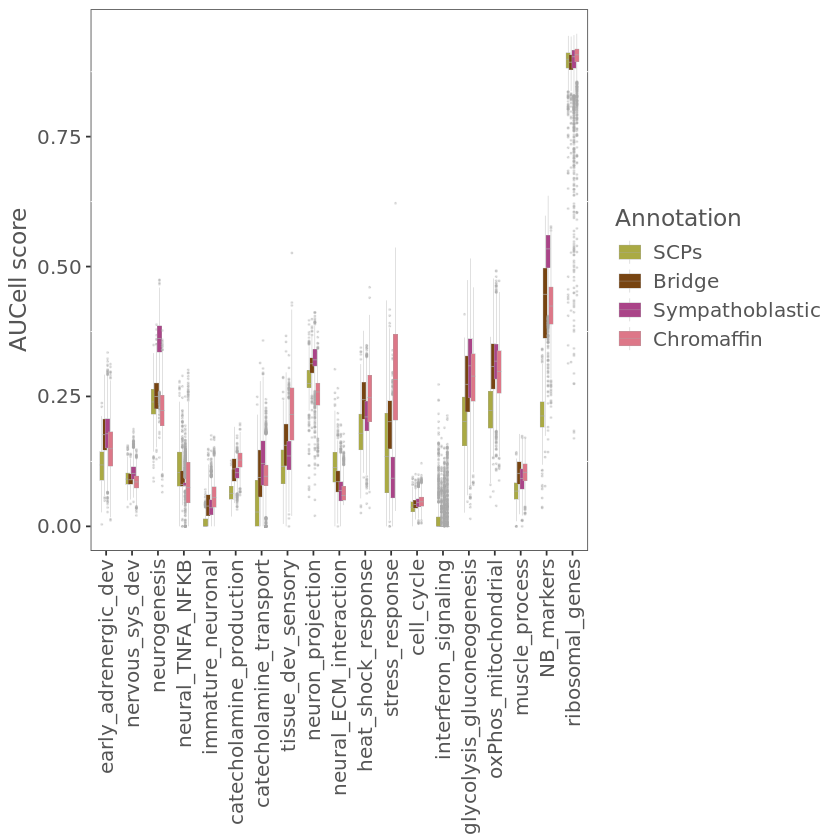

In [60]:
ggplot(df_long, aes(x = score_type, y = score_value, fill = Annotation)) +
              geom_boxplot(width = 0.65, position = position_dodge(width = 0.45), outlier.alpha = 0.3,
                             linewidth = 0.1, outlier.size = 0.2, color = 'dark grey') +
              scale_fill_manual(values = tol21rainbow[c(14,16,2,21)]) +
              ylab("AUCell score") +
              xlab(NULL) +
              mytheme_angledX

In [61]:
# write out source data

write.csv(df_long, '../source_data_figs/source_data_s5.csv')
